# 23CSE301 Machine Learning — Capstone Project
## Clustering Track — Review 2

**Team:** TASKMASTERS (Team 16)
**Dataset:** WTA Grand Slam Matches, 2018–2022 (Australian Open, Roland Garros, Wimbledon, US Open)
**Task:** Unsupervised discovery of match *types* from match statistics

---

### Problem statement

Each row is one women's Grand Slam singles match with serve and return statistics for both players. Without using any label, we want to group matches into types (for example, short one-sided matches, long close matches and serve-dominated matches) and describe what makes each type different.

The court **surface** is held back as a ground-truth variable. It is used **only after clustering**, to interpret the clusters, and never during fitting, as section 3.3 of the guidelines requires.

### Review 2 scope (rubric section 6, B1–B3)

| Rubric item | Where it is covered |
|---|---|
| B1 — Both algorithms fitted, labels obtained | Sections 4 (K-Means) and 5 (Agglomerative) |
| B2 — Silhouette, Davies-Bouldin, Calinski-Harabasz for both; Elbow curve; Dendrogram | Sections 4, 5, 6 |
| B3 — PCA 2-D plot for every algorithm; t-SNE for at least one | Sections 7 and 8 |

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
)
from scipy.cluster.hierarchy import dendrogram, linkage

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
CLUSTER_PALETTE = sns.color_palette("colorblind")

print("Libraries imported. Random state:", RANDOM_STATE)

Libraries imported. Random state: 42


## 1. Dataset loading and audit

In [2]:
df = pd.read_csv("wta-grand-slam-matches-2018to2022.csv")

print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
display(df.head())

Shape: (2413, 38)
Duplicate rows: 0


,tourney_name,surface,tourney_date,winner_seed,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,loser_seed,...,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,loser_rank
0,ROLAND GARROS,Clay,20180528,1,Simona Halep,R,168.0,ROU,26.6,NaN,...,3.0,66.0,40.0,18.0,9.0,11.0,4.0,11.0,1.0,83.0
1,ROLAND GARROS,Clay,20180528,NaN,Taylor Townsend,L,170.0,USA,22.1,NaN,...,4.0,55.0,29.0,18.0,12.0,9.0,2.0,5.0,72.0,222.0
2,ROLAND GARROS,Clay,20180528,NaN,Bethanie Mattek Sands,R,168.0,USA,33.1,NaN,...,4.0,62.0,40.0,30.0,9.0,9.0,3.0,5.0,202.0,59.0
3,ROLAND GARROS,Clay,20180528,NaN,Andrea Petkovic,R,180.0,GER,30.7,29,...,7.0,70.0,34.0,23.0,19.0,10.0,4.0,7.0,107.0,31.0
4,ROLAND GARROS,Clay,20180528,24,Daria Saville,R,166.0,AUS,24.2,NaN,...,6.0,123.0,75.0,42.0,20.0,15.0,7.0,14.0,25.0,49.0


In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
})
display(audit[audit["missing"] > 0])

incomplete = df["score"].str.contains("RET|W/O|DEF", na=False)
print("Matches ending in retirement / walkover / default:", incomplete.sum())
display(df["surface"].value_counts().to_frame("matches"))

,dtype,missing,missing_%
winner_seed,str,1139,47.20
winner_ht,float64,79,3.27
loser_seed,str,1755,72.73
loser_ht,float64,190,7.87
minutes,float64,133,5.51
w_ace,float64,11,0.46
w_df,float64,13,0.54
w_svpt,float64,11,0.46
w_1stIn,float64,11,0.46
w_1stWon,float64,11,0.46


Matches ending in retirement / walkover / default: 41


,matches
surface,
Hard,1270
Clay,635
Grass,508


**Audit observations.**
- 2,413 matches and 38 columns, with no duplicate rows.
- Seeds are missing for most players because unseeded players have no seed, so the seed columns are not used.
- 41 matches ended early (retirement, walkover or default). Their statistics describe an unfinished match, so they are removed.
- About 11 matches have no serve statistics at all and are removed too. `minutes` is missing for 133 matches and is not used as a feature.
- Surface split: Hard 1,270, Clay 635 and Grass 508 matches. This is kept only for interpretation after clustering.

## 2. Feature engineering and preprocessing

Raw counts such as aces or serve points mostly measure how **long** a match was. To describe what *kind* of match it was, we convert them into **rates** that are comparable across short and long matches:

| Feature | Definition | What it captures |
|---|---|---|
| `total_points` | winner + loser serve points | Match length |
| `winner_point_share` | share of all points won by the winner | How one-sided the match was |
| `winner_serve_won_pct` | winner's serve points won / winner's serve points | Winner's serve dominance |
| `loser_serve_won_pct` | loser's serve points won / loser's serve points | Loser's ability to hold serve |
| `ace_rate` | (winner + loser aces) / total points | Serve-power matches |
| `df_rate` | (winner + loser double faults) / total points | Serve errors |
| `bp_per_game` | break points faced / service games | How often serve came under pressure |

Identifier-like columns (dates, seeds, rankings, player names) are excluded on purpose: they describe *who* played, not *how* the match was played.

In [4]:
matches = df[~incomplete].dropna(subset=["w_svpt", "l_svpt", "w_SvGms", "l_SvGms"]).copy()
matches = matches[(matches["w_svpt"] > 0) & (matches["l_svpt"] > 0)]
print("Complete matches with statistics:", len(matches))


def build_match_features(m):
    total = m["w_svpt"] + m["l_svpt"]
    winner_serve_won = m["w_1stWon"] + m["w_2ndWon"]
    loser_serve_won = m["l_1stWon"] + m["l_2ndWon"]
    return pd.DataFrame({
        "total_points": total,
        "winner_point_share": (winner_serve_won + (m["l_svpt"] - loser_serve_won)) / total,
        "winner_serve_won_pct": winner_serve_won / m["w_svpt"],
        "loser_serve_won_pct": loser_serve_won / m["l_svpt"],
        "ace_rate": (m["w_ace"] + m["l_ace"]) / total,
        "df_rate": (m["w_df"] + m["l_df"]) / total,
        "bp_per_game": (m["w_bpFaced"] + m["l_bpFaced"]) / (m["w_SvGms"] + m["l_SvGms"]),
    }, index=m.index)


features = build_match_features(matches).replace([np.inf, -np.inf], np.nan)
FEATURES = features.columns.tolist()
print("Missing values after feature construction:\n", features.isna().sum()[features.isna().sum() > 0])
features = features.fillna(features.median())
display(features.describe().T.round(3))

Complete matches with statistics: 2372
Missing values after feature construction:
 df_rate        2
bp_per_game    2
dtype: int64


,count,mean,std,min,25%,50%,75%,max
total_points,2372.0,141.967,40.779,60.000,110.000,133.000,169.000,303.000
winner_point_share,2372.0,0.562,0.044,0.462,0.529,0.555,0.586,0.833
winner_serve_won_pct,2372.0,0.637,0.069,0.411,0.589,0.633,0.680,0.933
loser_serve_won_pct,2372.0,0.510,0.071,0.212,0.467,0.513,0.558,0.716
ace_rate,2372.0,0.041,0.028,0.000,0.021,0.036,0.057,0.184
df_rate,2372.0,0.050,0.024,0.000,0.031,0.047,0.064,0.156
bp_per_game,2372.0,0.755,0.323,0.125,0.571,0.737,0.900,11.000


### 2.1 EDA of the clustering features

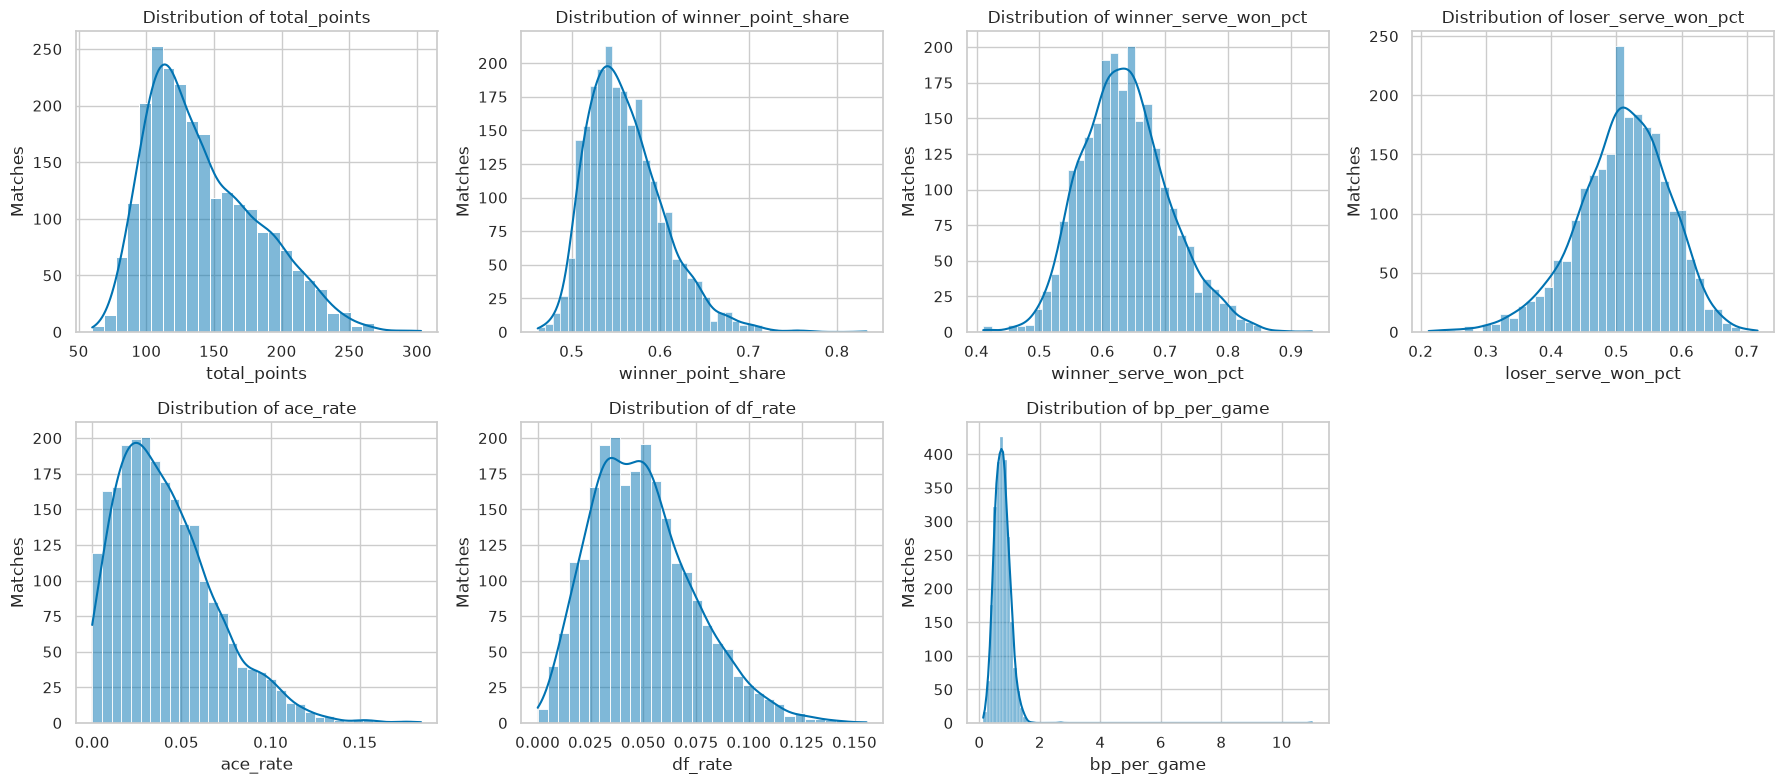

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, column in zip(axes.ravel(), FEATURES):
    sns.histplot(features[column], kde=True, ax=ax)
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Matches")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

**Distribution observations.** Most rates are roughly bell-shaped, but `bp_per_game`, `ace_rate` and `winner_point_share` have long right tails caused by a handful of extreme matches (e.g. a 6-0 6-0 rout). Distance-based clustering is very sensitive to such points — in a first attempt, complete/average/single linkage put **one or two extreme matches in their own clusters** and everything else in one giant cluster. We therefore cap (winsorise) each feature at its 1st and 99th percentile before scaling.

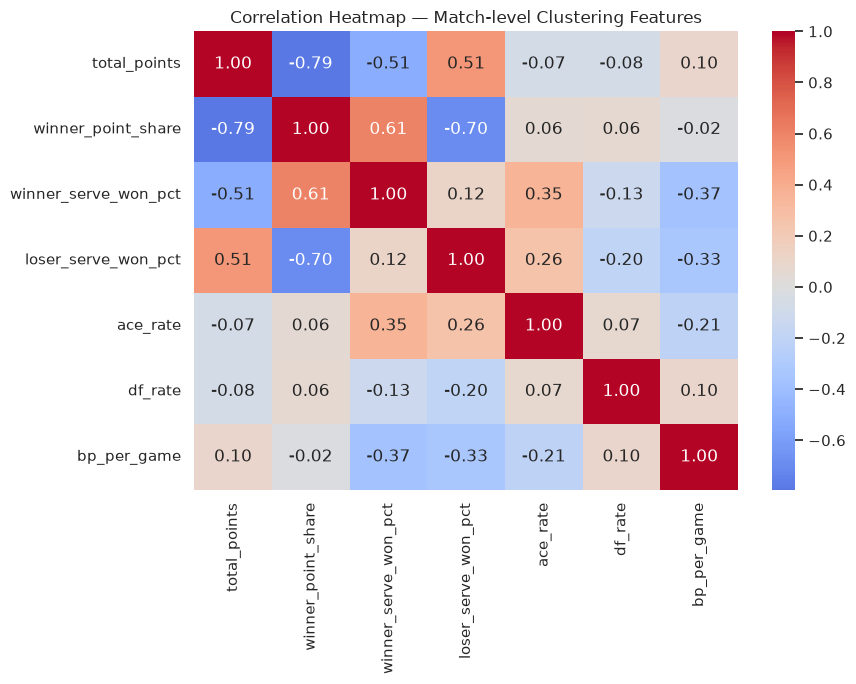

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(features.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — Match-level Clustering Features")
plt.tight_layout()
plt.show()

**Correlation observations.** `winner_point_share` is strongly negatively correlated with `total_points` and with `loser_serve_won_pct`: one-sided matches are short, and the loser rarely holds serve. `ace_rate` is almost independent of the other features, so it is likely to separate a distinct "serve-power" type of match. No pair is so highly correlated that a feature should be dropped.

In [7]:
# Winsorise at the 1st/99th percentile, then standardise.
# There is no train/test split in unsupervised learning, so the scaler is fitted on all matches.
lower, upper = features.quantile(0.01), features.quantile(0.99)
features_clipped = features.clip(lower, upper, axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_clipped)

print("Scaled matrix:", X_scaled.shape)
print("Column means ≈ 0:", np.allclose(X_scaled.mean(axis=0), 0))
print("Column std ≈ 1:", np.allclose(X_scaled.std(axis=0), 1))

Scaled matrix: (2372, 7)
Column means ≈ 0: True
Column std ≈ 1: True


## 3. Shared evaluation helper

All three mandatory internal metrics are computed by one function so every algorithm is scored identically:
- **Silhouette** (−1 to 1, higher is better): how much closer a point is to its own cluster than to the next one.
- **Davies-Bouldin** (≥ 0, lower is better): average similarity between each cluster and its most similar cluster.
- **Calinski-Harabasz** (higher is better): between-cluster variance divided by within-cluster variance.

In [8]:
def cluster_metrics(X, labels):
    return {
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X, labels),
        "Smallest cluster %": np.bincount(labels).min() / len(labels) * 100,
    }


def find_elbow(k_values, inertias):
    # Kneedle method: the k whose (normalised) inertia lies furthest below the straight line
    # joining the first and last point of the curve.
    k = np.asarray(k_values, dtype=float)
    y = np.asarray(inertias, dtype=float)
    k_norm = (k - k.min()) / (k.max() - k.min())
    y_norm = (y - y.min()) / (y.max() - y.min())
    distance = (1 - k_norm) - y_norm
    return int(k[np.argmax(distance)])

## 4. K-Means clustering

### 4.1 Elbow curve (inertia vs. k)

,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster %
k,,,,,
2,12454.991,0.225,1.643,789.500,46.248
3,10292.219,0.201,1.473,726.404,31.998
4,9138.283,0.184,1.489,644.863,18.297
5,8412.391,0.172,1.508,576.227,15.346
6,7781.703,0.168,1.459,536.478,12.732
7,7259.214,0.172,1.414,507.411,11.425
8,6925.115,0.161,1.482,472.006,9.064
9,6602.207,0.166,1.434,447.479,7.841
10,6340.457,0.155,1.455,424.829,6.788


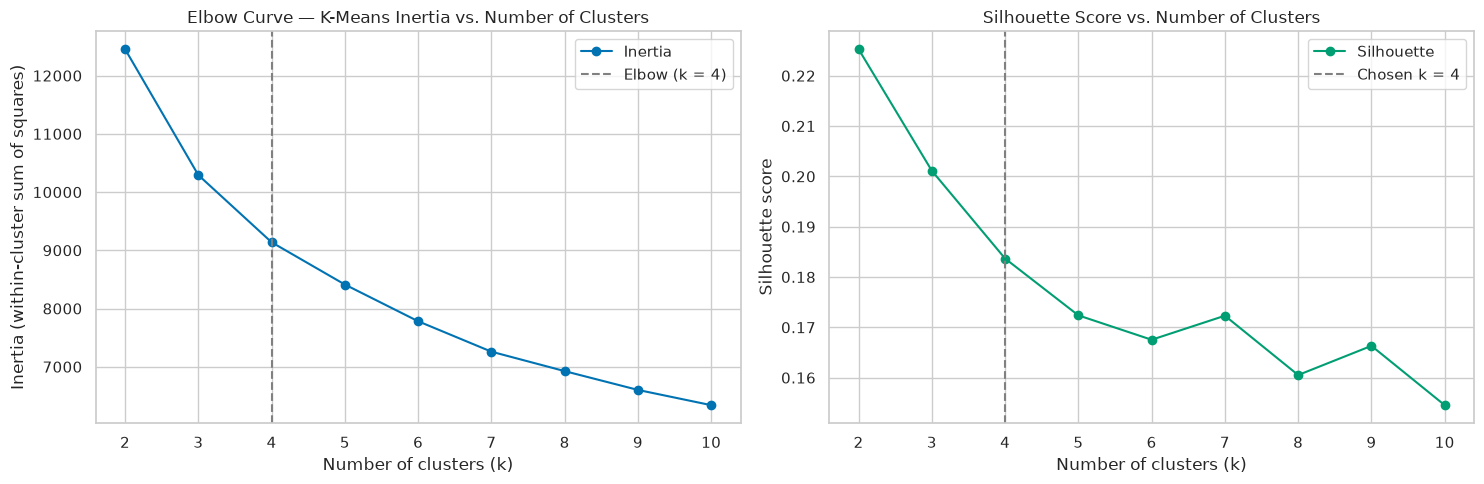

Elbow (kneedle) choice of k: 4


In [9]:
K_RANGE = range(2, 11)
elbow_rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    elbow_rows.append({"k": k, "Inertia": km.inertia_, **cluster_metrics(X_scaled, km.labels_)})
elbow_df = pd.DataFrame(elbow_rows).set_index("k")
display(elbow_df.round(3))

optimal_k = find_elbow(elbow_df.index, elbow_df["Inertia"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(elbow_df.index, elbow_df["Inertia"], marker="o", label="Inertia")
axes[0].axvline(optimal_k, color="grey", linestyle="--", label=f"Elbow (k = {optimal_k})")
axes[0].set_title("Elbow Curve — K-Means Inertia vs. Number of Clusters")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].legend()

axes[1].plot(elbow_df.index, elbow_df["Silhouette"], marker="o", color=CLUSTER_PALETTE[2], label="Silhouette")
axes[1].axvline(optimal_k, color="grey", linestyle="--", label=f"Chosen k = {optimal_k}")
axes[1].set_title("Silhouette Score vs. Number of Clusters")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Elbow (kneedle) choice of k:", optimal_k)

**Choosing k.** The inertia curve has no sharp elbow, which is normal for continuous match statistics. The kneedle method puts the elbow at **k = 4**. After k = 4 each extra cluster reduces inertia by less than 8%. The silhouette score is highest at k = 2 (0.225), but two clusters only split "long" from "short" matches. At k = 4 the silhouette is still 0.184, every cluster holds at least 18% of matches, and each cluster has a clear tennis meaning (section 9). We therefore use **k = 4** for both algorithms.

### 4.2 Final K-Means model

In [10]:
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=RANDOM_STATE)
kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_metrics = cluster_metrics(X_scaled, kmeans_labels)
display(pd.DataFrame([kmeans_metrics], index=[f"K-Means (k={optimal_k})"]).round(4))
display(pd.Series(kmeans_labels).value_counts().sort_index().rename("matches").to_frame())

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster %
K-Means (k=4),0.1837,1.4893,644.8629,18.2968


,matches
0,678
1,600
2,434
3,660


## 5. Agglomerative hierarchical clustering

### 5.1 Comparing linkage strategies
We fit the same number of clusters with all four linkage strategies. A linkage is only accepted if its smallest cluster contains at least 5% of the matches — otherwise a high silhouette just reflects a few isolated outliers rather than a useful grouping.

In [11]:
LINKAGES = ["ward", "complete", "average", "single"]
MIN_CLUSTER_SHARE = 5.0

linkage_rows, linkage_labels = [], {}
for method in LINKAGES:
    labels = AgglomerativeClustering(n_clusters=optimal_k, linkage=method).fit_predict(X_scaled)
    linkage_labels[method] = labels
    linkage_rows.append({"Linkage": method, **cluster_metrics(X_scaled, labels),
                         "Cluster sizes": np.bincount(labels).tolist()})

linkage_df = pd.DataFrame(linkage_rows).set_index("Linkage")
linkage_df["Valid (≥5% per cluster)"] = linkage_df["Smallest cluster %"] >= MIN_CLUSTER_SHARE
display(linkage_df.round(4))

best_linkage = linkage_df[linkage_df["Valid (≥5% per cluster)"]]["Silhouette"].idxmax()
hier_labels = linkage_labels[best_linkage]
hier_metrics = cluster_metrics(X_scaled, hier_labels)
print("Selected linkage:", best_linkage)

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster %,Cluster sizes,Valid (≥5% per cluster)
Linkage,,,,,,
ward,0.1329,1.7256,487.6621,15.6830,"[694, 906, 400, 372]",True
complete,0.1042,1.9531,435.5751,16.1889,"[538, 557, 893, 384]",True
average,0.0953,1.0145,94.0144,0.0422,"[119, 2237, 1, 15]",False
single,0.1349,0.5590,3.0984,0.0422,"[2369, 1, 1, 1]",False


Selected linkage: ward


**Linkage comparison.**
- **Single** linkage chains points together, giving one cluster of 2,369 matches and three single-match clusters. Its Davies-Bouldin score looks excellent (0.56) only because the "clusters" are isolated outliers.
- **Average** linkage has the same problem: one of its clusters is a single match.
- **Complete** and **Ward** both give balanced clusters (all at least 15% of matches). **Ward** wins on all three metrics (silhouette 0.133 vs 0.104, Davies-Bouldin 1.73 vs 1.95, Calinski-Harabasz 488 vs 436). This is expected, because Ward, like K-Means, minimises within-cluster variance.

This is why we pick the linkage by silhouette **only among non-degenerate solutions**. Picking by raw silhouette would choose single linkage, which is not a useful grouping.

### 5.2 Dendrograms

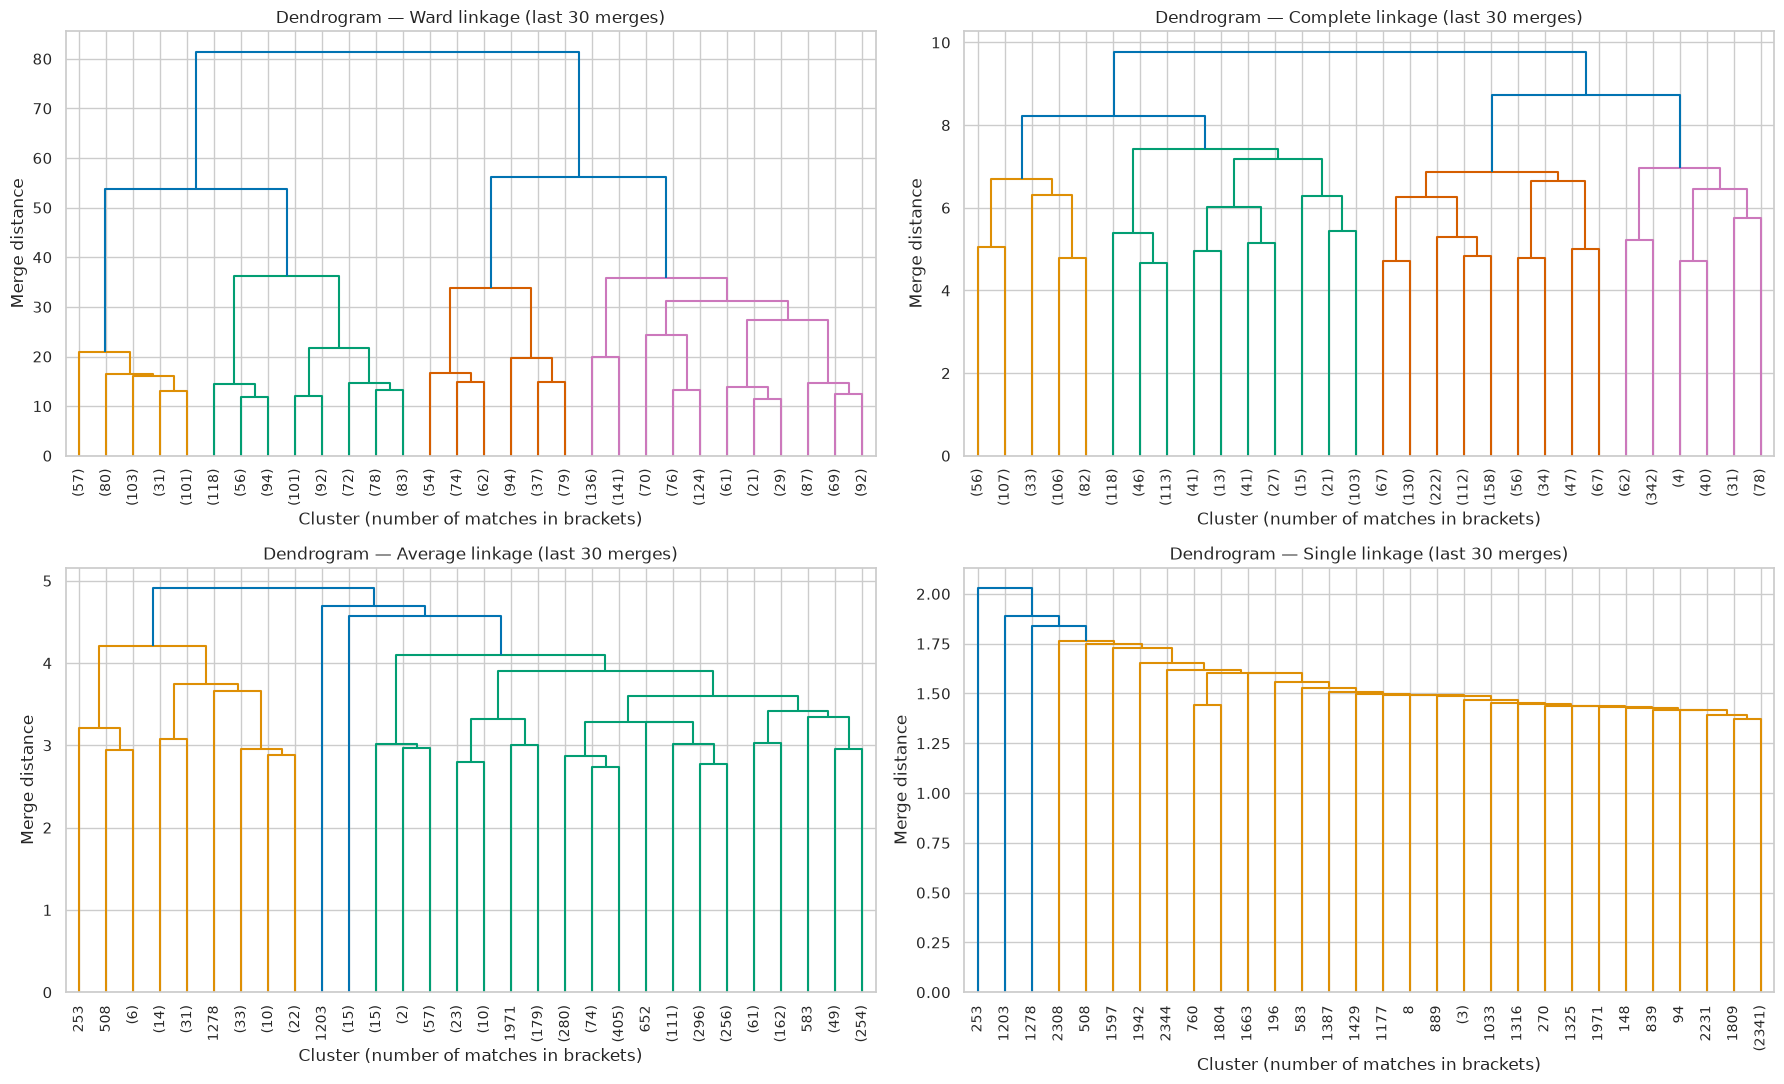

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, method in zip(axes.ravel(), LINKAGES):
    Z = linkage(X_scaled, method=method)
    dendrogram(Z, truncate_mode="lastp", p=30, ax=ax, show_leaf_counts=True,
               leaf_rotation=90, color_threshold=Z[-(optimal_k - 1), 2])
    ax.set_title(f"Dendrogram — {method.capitalize()} linkage (last 30 merges)")
    ax.set_xlabel("Cluster (number of matches in brackets)")
    ax.set_ylabel("Merge distance")
plt.tight_layout()
plt.show()

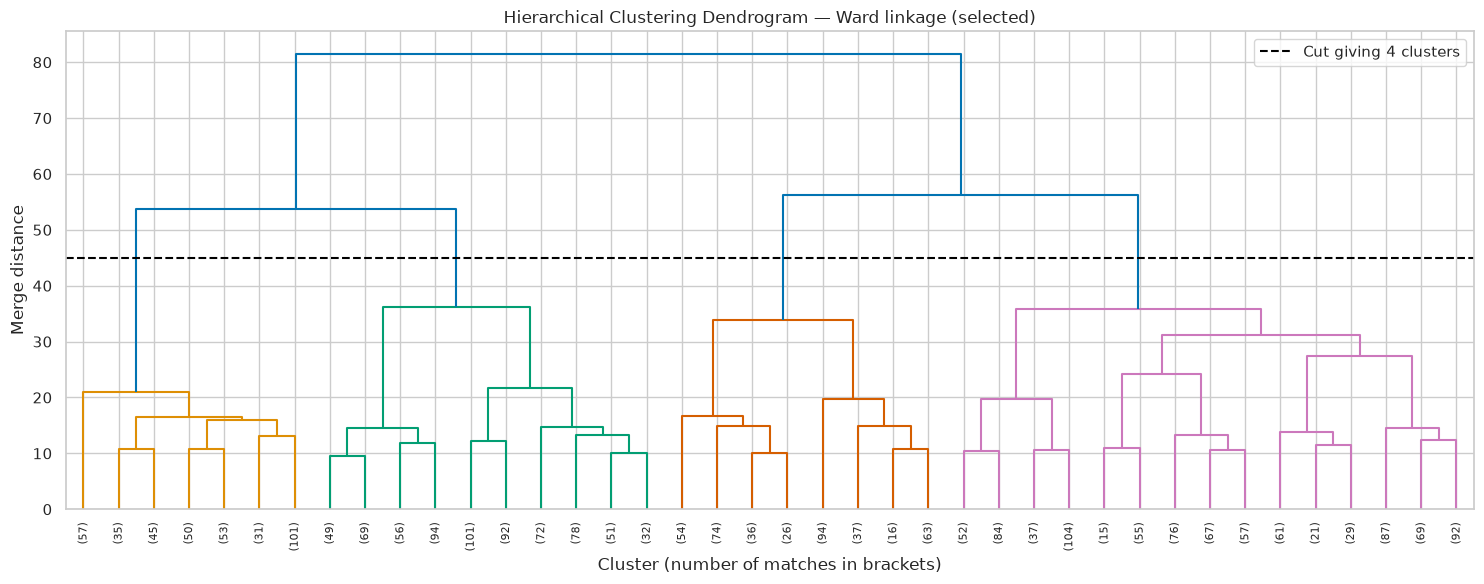

In [13]:
Z_best = linkage(X_scaled, method=best_linkage)
cut_height = (Z_best[-optimal_k, 2] + Z_best[-(optimal_k - 1), 2]) / 2

plt.figure(figsize=(15, 6))
dendrogram(Z_best, truncate_mode="lastp", p=40, show_leaf_counts=True,
           leaf_rotation=90, color_threshold=cut_height)
plt.axhline(cut_height, color="black", linestyle="--", label=f"Cut giving {optimal_k} clusters")
plt.title(f"Hierarchical Clustering Dendrogram — {best_linkage.capitalize()} linkage (selected)")
plt.xlabel("Cluster (number of matches in brackets)")
plt.ylabel("Merge distance")
plt.legend()
plt.tight_layout()
plt.show()

**Dendrogram observations.** Ward linkage produces a balanced tree with a clear jump in merge distance just above the cut, which supports the chosen number of clusters. Single and average linkage show the typical *chaining* behaviour: points join one long chain one at a time, so cutting them gives one giant cluster plus a few stragglers.

## 6. Algorithm comparison (rubric B2)

In [14]:
comparison_df = pd.DataFrame({
    f"K-Means (k={optimal_k})": kmeans_metrics,
    f"Agglomerative ({best_linkage}, k={optimal_k})": hier_metrics,
}).T

display(
    comparison_df.style
    .format({"Silhouette": "{:.4f}", "Davies-Bouldin": "{:.4f}",
             "Calinski-Harabasz": "{:.1f}", "Smallest cluster %": "{:.1f}"})
    .highlight_max(subset=["Silhouette", "Calinski-Harabasz"], color="#c6e9c3")
    .highlight_min(subset=["Davies-Bouldin"], color="#c6e9c3")
)
print("Agreement between the two partitions (Adjusted Rand Index):",
      round(adjusted_rand_score(kmeans_labels, hier_labels), 4))

,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster %
K-Means (k=4),0.1837,1.4893,644.9,18.3
"Agglomerative (ward, k=4)",0.1329,1.7256,487.7,15.7


Agreement between the two partitions (Adjusted Rand Index): 0.2486


**Comparison.** K-Means beats Ward hierarchical clustering on **all three** metrics: higher silhouette (0.184 vs 0.133), lower Davies-Bouldin (1.49 vs 1.73) and higher Calinski-Harabasz (645 vs 488). K-Means directly optimises compact, roughly spherical clusters, and Ward's merges cannot be undone later. The two partitions agree only moderately (ARI = 0.25). They split the same continuous cloud along slightly different directions, so the labels do not line up exactly. **K-Means is selected as the final clustering model.**

The absolute silhouette values (0.13–0.18) show that the clusters **overlap**. Match style changes gradually, so the clusters are best read as regions of one continuum of match types, not as clearly separated groups.

## 7. PCA cluster visualisation (mandatory)

Explained variance — PC1: 37.4%, PC2: 29.4%, total: 66.8%


,PC1,PC2
total_points,-0.559,-0.025
winner_point_share,0.599,0.080
winner_serve_won_pct,0.413,-0.437
loser_serve_won_pct,-0.373,-0.509
ace_rate,0.092,-0.419
df_rate,0.063,0.192
bp_per_game,-0.078,0.575


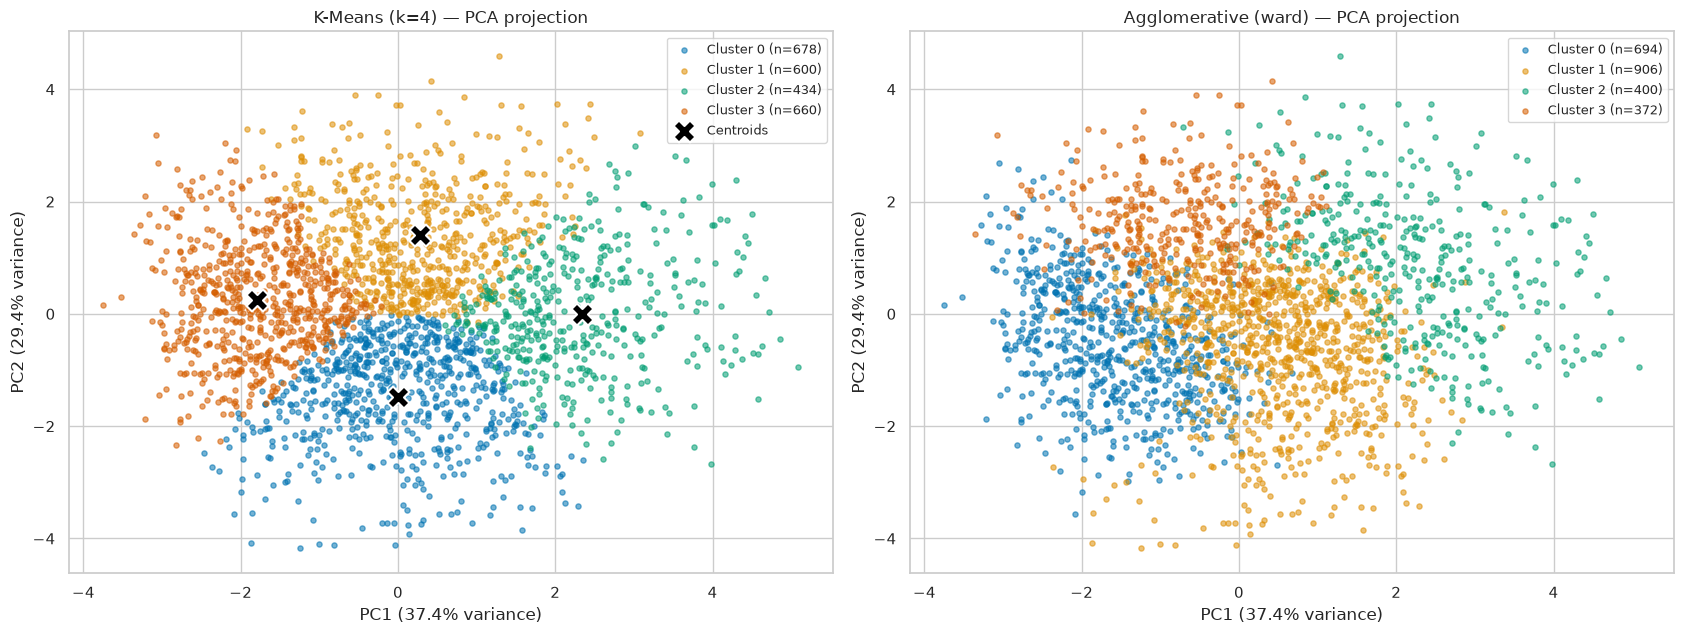

In [15]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Explained variance — PC1: {:.1%}, PC2: {:.1%}, total: {:.1%}".format(
    *pca.explained_variance_ratio_, pca.explained_variance_ratio_.sum()))

loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"])
display(loadings.round(3))


def plot_clusters_2d(ax, coords, labels, title, xlabel, ylabel, centres=None):
    for cluster in np.unique(labels):
        mask = labels == cluster
        ax.scatter(coords[mask, 0], coords[mask, 1], s=14, alpha=0.55,
                   color=CLUSTER_PALETTE[cluster], label=f"Cluster {cluster} (n={mask.sum()})")
    if centres is not None:
        ax.scatter(centres[:, 0], centres[:, 1], marker="X", s=250, color="black",
                   edgecolor="white", linewidth=1.5, label="Centroids")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(loc="best", fontsize=9)


pc_x = f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)"
pc_y = f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)"

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
plot_clusters_2d(axes[0], X_pca, kmeans_labels, f"K-Means (k={optimal_k}) — PCA projection",
                 pc_x, pc_y, centres=pca.transform(kmeans.cluster_centers_))
plot_clusters_2d(axes[1], X_pca, hier_labels, f"Agglomerative ({best_linkage}) — PCA projection", pc_x, pc_y)
plt.tight_layout()
plt.show()

**PCA observations.** The first two components explain about 67% of the variance. **PC1** is a "one-sidedness" axis: high winner point share and short matches on the right, long close matches on the left. **PC2** separates serve-dominated matches (high ace rate, both players holding serve) from break-heavy matches (many break points). The K-Means clusters fall into four regions of this plane, with centroids well apart. Ward's clusters cover similar regions but with different boundaries, consistent with the ARI of 0.25.

## 8. t-SNE cluster visualisation (encouraged)

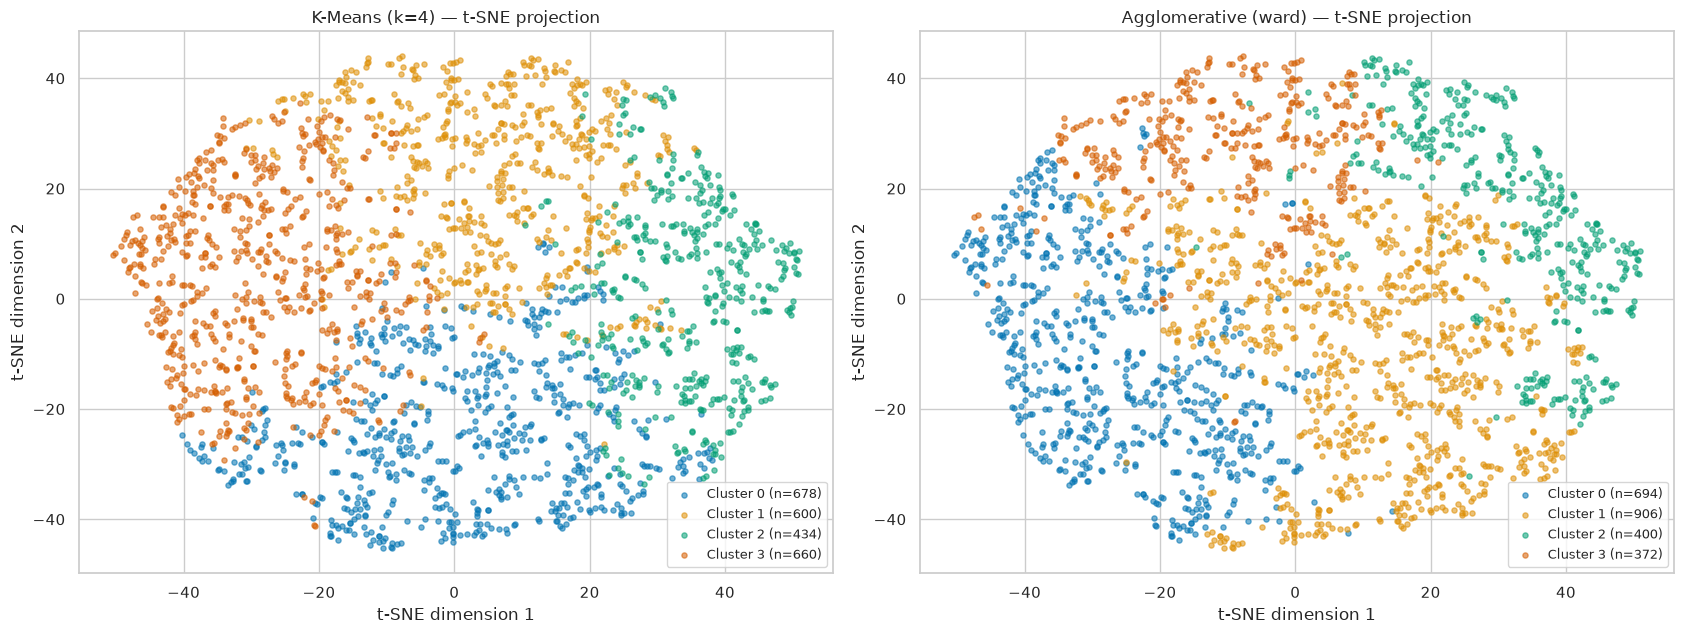

In [16]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
plot_clusters_2d(axes[0], X_tsne, kmeans_labels, f"K-Means (k={optimal_k}) — t-SNE projection",
                 "t-SNE dimension 1", "t-SNE dimension 2")
plot_clusters_2d(axes[1], X_tsne, hier_labels, f"Agglomerative ({best_linkage}) — t-SNE projection",
                 "t-SNE dimension 1", "t-SNE dimension 2")
plt.tight_layout()
plt.show()

**t-SNE observations.** t-SNE keeps local neighbourhoods rather than global distances, so the clusters look like neighbouring regions of one continuous cloud rather than separate islands. This matches the moderate silhouette scores: match styles change gradually rather than falling into sharply separated groups.

## 9. Cluster interpretation

### 9.1 Cluster profiles

,matches,total_points,winner_point_share,winner_serve_won_pct,loser_serve_won_pct,ace_rate,df_rate,bp_per_game
cluster,,,,,,,,
0,678,137.901,0.553,0.676,0.566,0.061,0.045,0.547
1,600,126.613,0.569,0.598,0.458,0.029,0.060,0.957
2,434,96.933,0.628,0.710,0.442,0.043,0.048,0.692
3,660,189.715,0.520,0.584,0.543,0.032,0.046,0.827


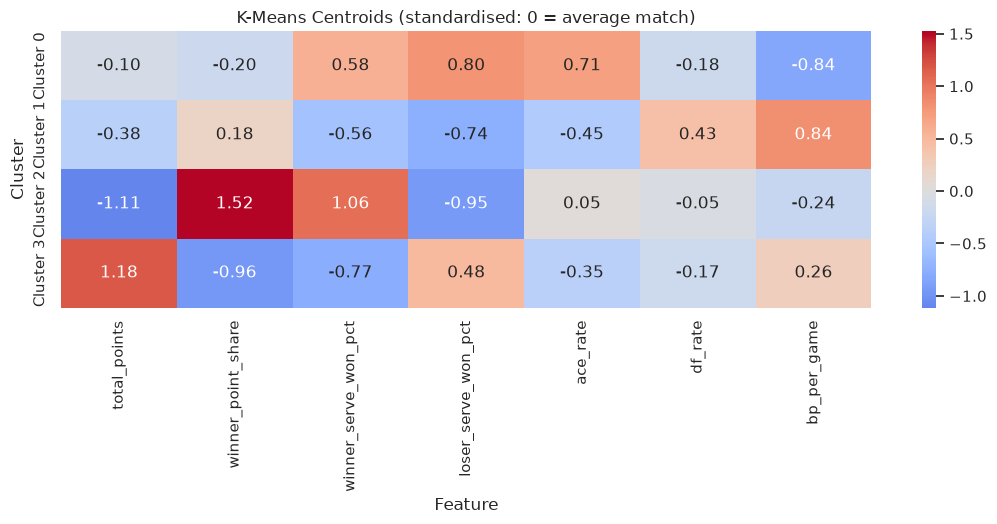

In [17]:
profile = features.assign(cluster=kmeans_labels).groupby("cluster")[FEATURES].mean()
profile.insert(0, "matches", np.bincount(kmeans_labels))
display(profile.round(3))

centroid_z = pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES)
plt.figure(figsize=(11, 3 + 0.6 * optimal_k))
sns.heatmap(centroid_z, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            yticklabels=[f"Cluster {c}" for c in range(optimal_k)])
plt.title("K-Means Centroids (standardised: 0 = average match)")
plt.xlabel("Feature")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

**Cluster interpretation (K-Means, k = 4):**

| Cluster | Matches | Profile | Suggested name |
|---:|---:|---|---|
| 0 | 678 | Highest ace rate (6.1%), both players win most service points, fewest break points per game (0.55) | **Serve-dominated** |
| 1 | 600 | Both players lose many service points (winner wins only 60%), most break points (0.96 per game), highest double-fault rate | **Break-heavy / return-dominated** |
| 2 | 434 | Shortest matches (~97 points), winner takes 63% of all points and 71% of serve points | **One-sided routs** |
| 3 | 660 | Longest matches (~190 points), winner takes only 52% of points | **Long, close battles** |

### 9.2 Post-hoc validation against surface (ground truth used only after fitting)

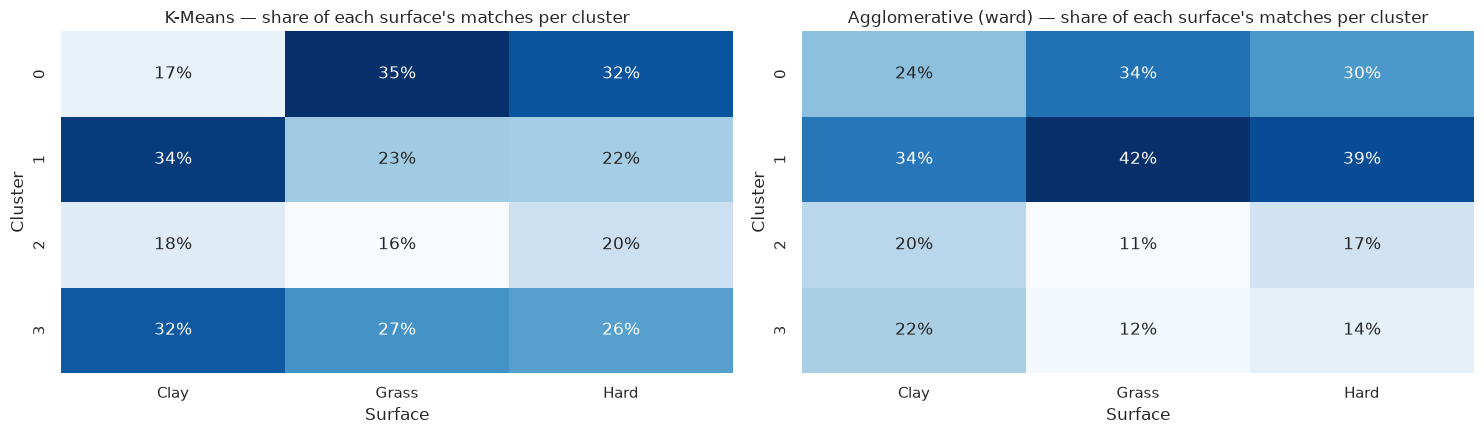

Adjusted Rand Index vs. surface — K-Means: 0.0092
Adjusted Rand Index vs. surface — Agglomerative: 0.0054


In [18]:
surface = matches["surface"].values

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, labels, name in [(axes[0], kmeans_labels, "K-Means"), (axes[1], hier_labels, f"Agglomerative ({best_linkage})")]:
    table = pd.crosstab(pd.Series(labels, name="Cluster"), pd.Series(surface, name="Surface"), normalize="columns")
    sns.heatmap(table, annot=True, fmt=".0%", cmap="Blues", ax=ax, cbar=False)
    ax.set_title(f"{name} — share of each surface's matches per cluster")
    ax.set_xlabel("Surface")
    ax.set_ylabel("Cluster")
plt.tight_layout()
plt.show()

print("Adjusted Rand Index vs. surface — K-Means:", round(adjusted_rand_score(surface, kmeans_labels), 4))
print("Adjusted Rand Index vs. surface — Agglomerative:", round(adjusted_rand_score(surface, hier_labels), 4))

**Validation observations.** The ARI against surface is close to 0, so the clusters are **not** just the surfaces under another name. They group matches by *how* they were played. The surface mix within clusters still matches tennis knowledge:
- **Clay** matches are over-represented in the *break-heavy* cluster (34% of clay matches vs 22–23% on grass/hard). Slow clay courts weaken the serve.
- **Grass** and **hard** matches are about twice as likely as clay matches to be *serve-dominated* (35% / 32% vs 17%). Fast courts reward the serve.

The labels were used only here, after fitting, as section 3.3 of the guidelines requires.

## 10. Summary and conclusions

| Algorithm | k | Silhouette ↑ | Davies-Bouldin ↓ | Calinski-Harabasz ↑ |
|---|---:|---:|---:|---:|
| **K-Means** (selected) | 4 | **0.1837** | **1.4893** | **644.9** |
| Agglomerative (Ward) | 4 | 0.1329 | 1.7256 | 487.7 |

**Key takeaways**
1. **Feature design:** converting raw counts into rates and match-level shares, and capping extreme values, turned degenerate one-giant-cluster solutions into four balanced, interpretable clusters.
2. **k = 4**, chosen with the elbow (kneedle) method and checked with silhouette, cluster sizes and interpretability.
3. **K-Means beats Ward** on every metric. Single and average linkage are rejected because they isolate outliers.
4. **Interpretable match types:** serve-dominated, break-heavy, one-sided and long close matches. Their surface mix agrees with tennis knowledge even though surface was never used in fitting.
5. **Limitation:** silhouette scores below 0.2 show that the match types overlap. The clusters are a useful summary, not sharply separated groups.

### Review 2 checklist
- [x] B1 — K-Means and Agglomerative clustering fitted, labels obtained, no errors
- [x] B2 — Silhouette, Davies-Bouldin and Calinski-Harabasz for both algorithms, plus an Elbow curve and Dendrograms (all four linkages, with the selected one cut at k)
- [x] B3 — PCA 2-D plot with cluster colours for both algorithms, plus t-SNE for both
- [x] Ground truth (surface) used only for interpretation after fitting